# Вариант 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Практическая работа №7: Исследовательский анализ данных и базовая визуализация

**Цель работы:**
Научиться выполнять исследовательский анализ данных (EDA), изучать распределения числовых и категориальных признаков, находить выбросы и аномалии, анализировать зависимости между переменными и строить базовые визуализации с помощью matplotlib и seaborn.

### Датасеты для работы:
- `data/orders_2024_01.csv`
- `data/orders_2024_02.csv`
- `data/orders_2024_03.csv`

### Подготовка окружения и данных

In [2]:
orders_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]

df_orders = pd.concat([pd.read_csv(f) for f in orders_files], ignore_index=True)
df_orders["order_datetime"] = pd.to_datetime(df_orders["order_datetime"])
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]

print(df_orders.head())
print(df_orders.info())
print(df_orders.describe())

   order_id  user_id      order_datetime  ...  quantity    status   revenue
0         1     1044 2024-01-03 18:39:26  ...         1  refunded  14038.15
1         2     1079 2024-01-03 17:45:43  ...         1      paid   9172.60
2         3     1041 2024-01-06 22:46:38  ...         2      paid  18070.52
3         4     1083 2024-01-08 21:03:51  ...         3      paid  45702.99
4         5     1068 2024-01-03 23:26:53  ...         2      paid   8268.76

[5 rows x 8 columns]
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        15000 non-null  int64         
 1   user_id         15000 non-null  int64         
 2   order_datetime  15000 non-null  datetime64[us]
 3   product_id      15000 non-null  int64         
 4   price           15000 non-null  float64       
 5   quantity        15000 non-null  int64         
 6   stat

### Задание 1. Построить histogram для price

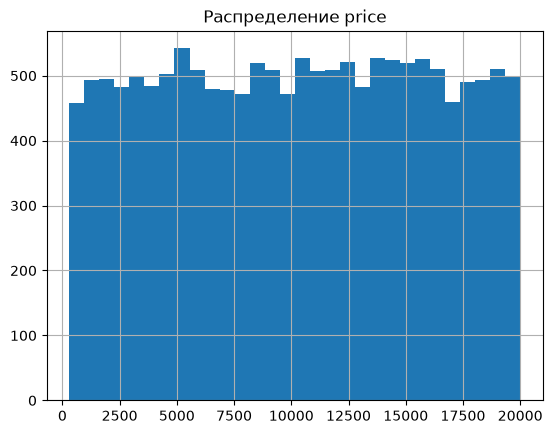

In [3]:
df_orders["price"].hist(bins=30)
plt.title("Распределение price")
plt.show()

### Задание 2. Построить boxplot для price

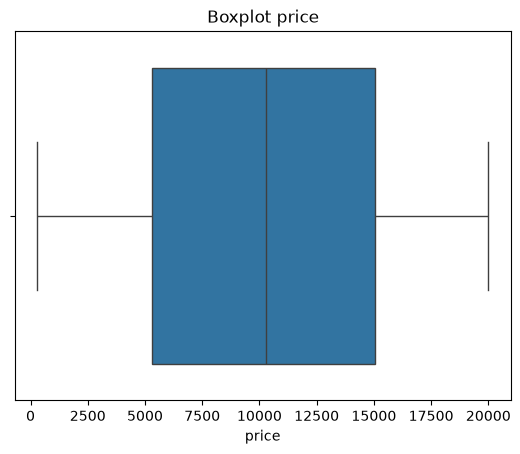

In [4]:
sns.boxplot(x=df_orders["price"])
plt.title("Boxplot price")
plt.show()

### Задание 3. Найти количество выбросов по price через IQR

In [5]:
q1 = df_orders["price"].quantile(0.25)
q3 = df_orders["price"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df_orders[(df_orders["price"] < lower) | (df_orders["price"] > upper)]
print("Q1 (25%):", q1)
print("Q3 (75%):", q3)
print("IQR:", iqr)
print("Нижняя граница (lower):", lower)
print("Верхняя граница (upper):", upper)
print("Количество выбросов:", len(outliers))

Q1 (25%): 5304.9575
Q3 (75%): 15050.532500000001
IQR: 9745.575
Нижняя граница (lower): -9313.405
Верхняя граница (upper): 29668.895000000004
Количество выбросов: 0


### Задание 4. Построить bar chart по status

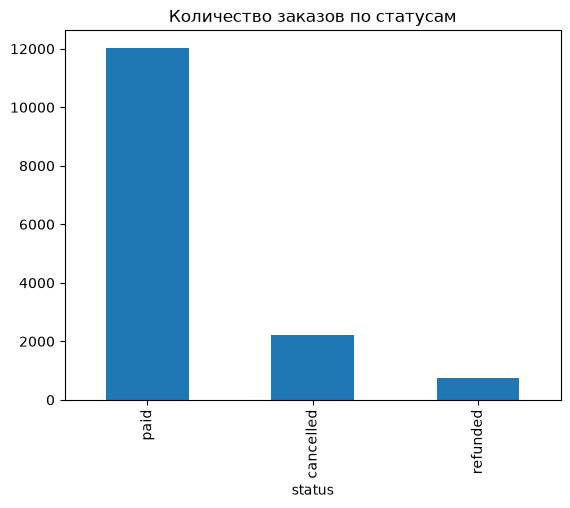

In [6]:
df_orders["status"].value_counts().plot(kind="bar")
plt.title("Количество заказов по статусам")
plt.show()

### Задание 5. Сделать краткий вывод по распределению цен

In [7]:
print("Краткий вывод по распределению цен:")
print("1. Диапазон цен составляет от", df_orders["price"].min(), "до", df_orders["price"].max(), "руб.")
print("2. Среднее значение (", round(df_orders["price"].mean(), 2), "руб.) практически равно медиане (", round(df_orders["price"].median(), 2), "руб.), что указывает на симметричное, близкое к равномерному распределение цен без перекосов.")
print("3. Расчёт по формуле межквартильного размаха 1.5*IQR показал 0 выбросов, так как все цены находятся строго внутри границ [", round(lower, 2), ",", round(upper, 2), "]. Экстремальные аномалии отсутствуют.")

Краткий вывод по распределению цен:
1. Диапазон цен составляет от 300.26 до 19998.96 руб.
2. Среднее значение ( 10207.38 руб.) практически равно медиане ( 10267.21 руб.), что указывает на симметричное, близкое к равномерному распределение цен без перекосов.
3. Расчёт по формуле межквартильного размаха 1.5*IQR показал 0 выбросов, так как все цены находятся строго внутри границ [ -9313.41 , 29668.9 ]. Экстремальные аномалии отсутствуют.
